In [1]:
from nn import *
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
mnist_train = pd.read_csv("mnist_train.csv", header=None)
mnist_test = pd.read_csv("mnist_test.csv", header=None)


In [3]:
Y = mnist_train[0].to_numpy()
Y = Y.reshape((Y.shape[0],1))
X = mnist_train.drop([0], axis=1).to_numpy()
X_scaled = X / 255

In [4]:
Y_onehot = np.zeros((Y.shape[0],10))
Y_onehot[np.arange(Y.shape[0]), Y.flatten()] = 1

In [5]:
np.random.seed(123)

In [6]:

X_train, Y_train, X_val, Y_val = train_val_split(X_scaled, Y_onehot, 0.9)

In [7]:
Y_test = mnist_test[0].to_numpy()
Y_test = Y_test.reshape((Y_test.shape[0],1))
X_test = mnist_test.drop([0], axis=1).to_numpy()
X_test_scaled = X_test / 255

In [8]:
Y_test_onehot = np.zeros((Y_test.shape[0],10))
Y_test_onehot[np.arange(Y_test.shape[0]), Y_test.flatten()] = 1

In [9]:
nn = NeuralNetwork([Layer(64, ReLu()),
                    Layer(64, ReLu()),
                    Layer(10, Identity())],
                    loss_function=CrossEntropy())

nn.train(X_train, Y_train, epochs=20, batch_size=500, learn_rate=0.05, X_val=X_val, Y_val=Y_val)

Average batch loss in epoch 0: 1.1737
Average batch loss in epoch 1: 0.4474
Average batch loss in epoch 2: 0.3514
Average batch loss in epoch 3: 0.3095
Average batch loss in epoch 4: 0.2837
Average batch loss in epoch 5: 0.2639
Average batch loss in epoch 6: 0.2492
Average batch loss in epoch 7: 0.2366
Average batch loss in epoch 8: 0.2254
Average batch loss in epoch 9: 0.2159
Average batch loss in epoch 10: 0.2066
Average batch loss in epoch 11: 0.1992
Average batch loss in epoch 12: 0.192
Average batch loss in epoch 13: 0.1854
Average batch loss in epoch 14: 0.179
Average batch loss in epoch 15: 0.1732
Average batch loss in epoch 16: 0.1677
Average batch loss in epoch 17: 0.163
Average batch loss in epoch 18: 0.1583
Average batch loss in epoch 19: 0.154


<Axes: >

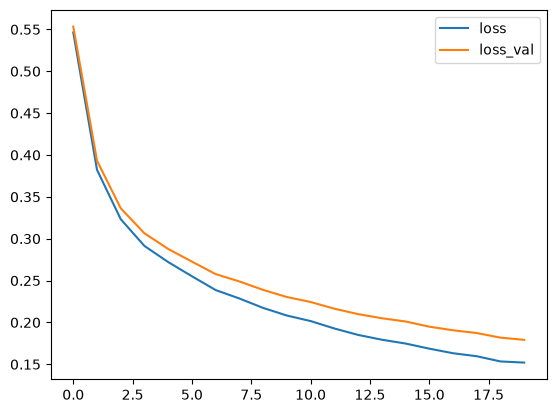

In [10]:
loss = pd.Series(nn.epoch_losses)
loss_val = pd.Series(nn.epoch_losses_val)

pd.DataFrame(data={"loss": loss, "loss_val": loss_val}).plot.line()

0     0.848000
1     0.890500
2     0.904000
3     0.911500
4     0.917833
5     0.918667
6     0.925500
7     0.927000
8     0.931833
9     0.935667
10    0.936500
11    0.938833
12    0.940333
13    0.941000
14    0.942333
15    0.946167
16    0.945667
17    0.947167
18    0.948000
19    0.947833
dtype: float64

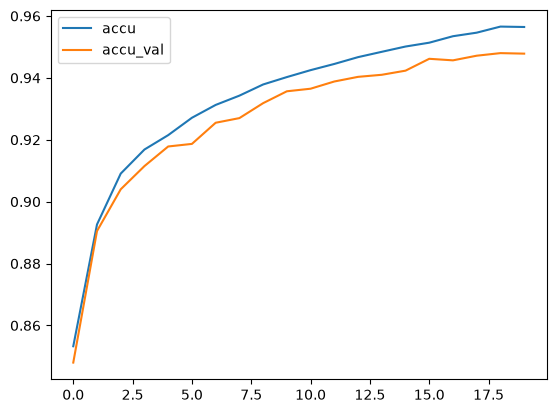

In [11]:
loss = pd.Series(nn.epoch_accu)
loss_val = pd.Series(nn.epoch_accu_val)

pd.DataFrame(data={"accu": loss, "accu_val": loss_val}).plot.line()
pd.Series(nn.epoch_accu_val)

In [12]:
# Min val loss
argmin = np.argmin(nn.epoch_losses_val)
argmin


np.int64(19)

In [13]:
# Val loss argmin vs last epoch
nn.epoch_losses_val[argmin] - nn.epoch_losses_val[-1]

np.float64(0.0)

In [14]:
nn.epoch_accu_val[argmin] - nn.epoch_accu_val[-1]

np.float64(0.0)